# 一、逻辑斯蒂回归

In [2]:
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 自实现模型（models/exp1/）
sys.path.insert(0, ".")
from models.exp1.sigmoid import sigmoid as my_sigmoid
from models.exp1.sigmoid import LogisticRegression as MyLogisticRegression
from models.exp1.LDA import LinearDiscriminantAnalysis as MyLDA


/home/yukari/PycharmProjects/machine_learning/.venv/lib/python3.12/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 13] Permission denied.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


## a.编写Python代码实现Logistic 回归，并简单展示Sigmoid函数

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)
y = sigmoid(z)

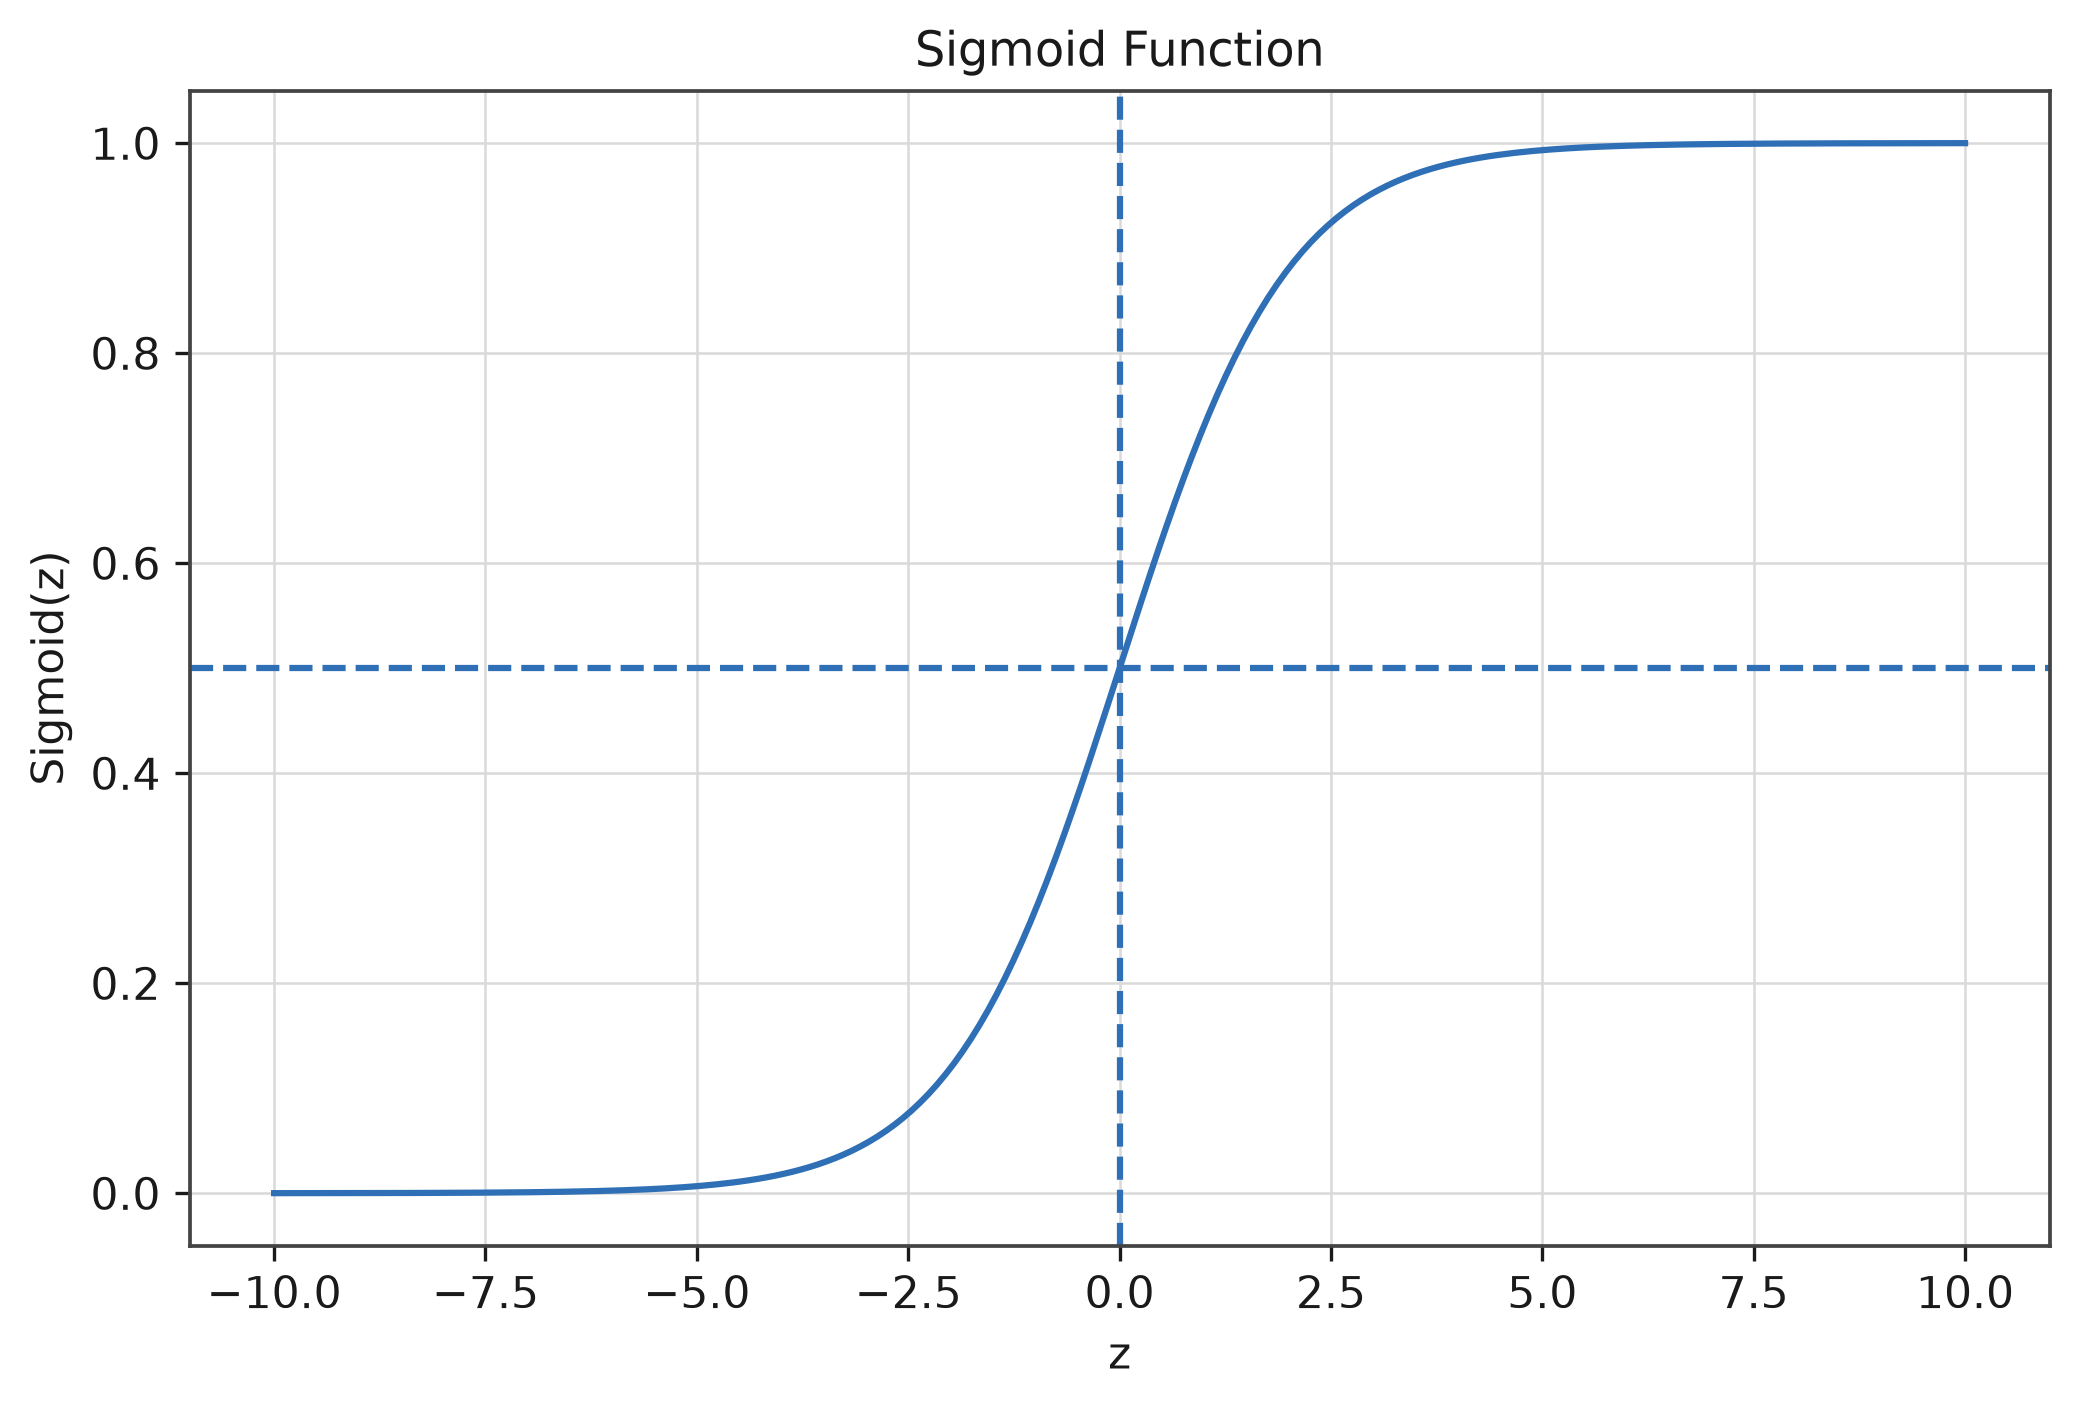

In [4]:
# 绘制 Sigmoid
plt.figure(figsize=(8, 5))
plt.plot(z, y)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Sigmoid Function")
plt.grid(True)
plt.show()

公式实现与自实现的最大绝对误差：5.55e-17


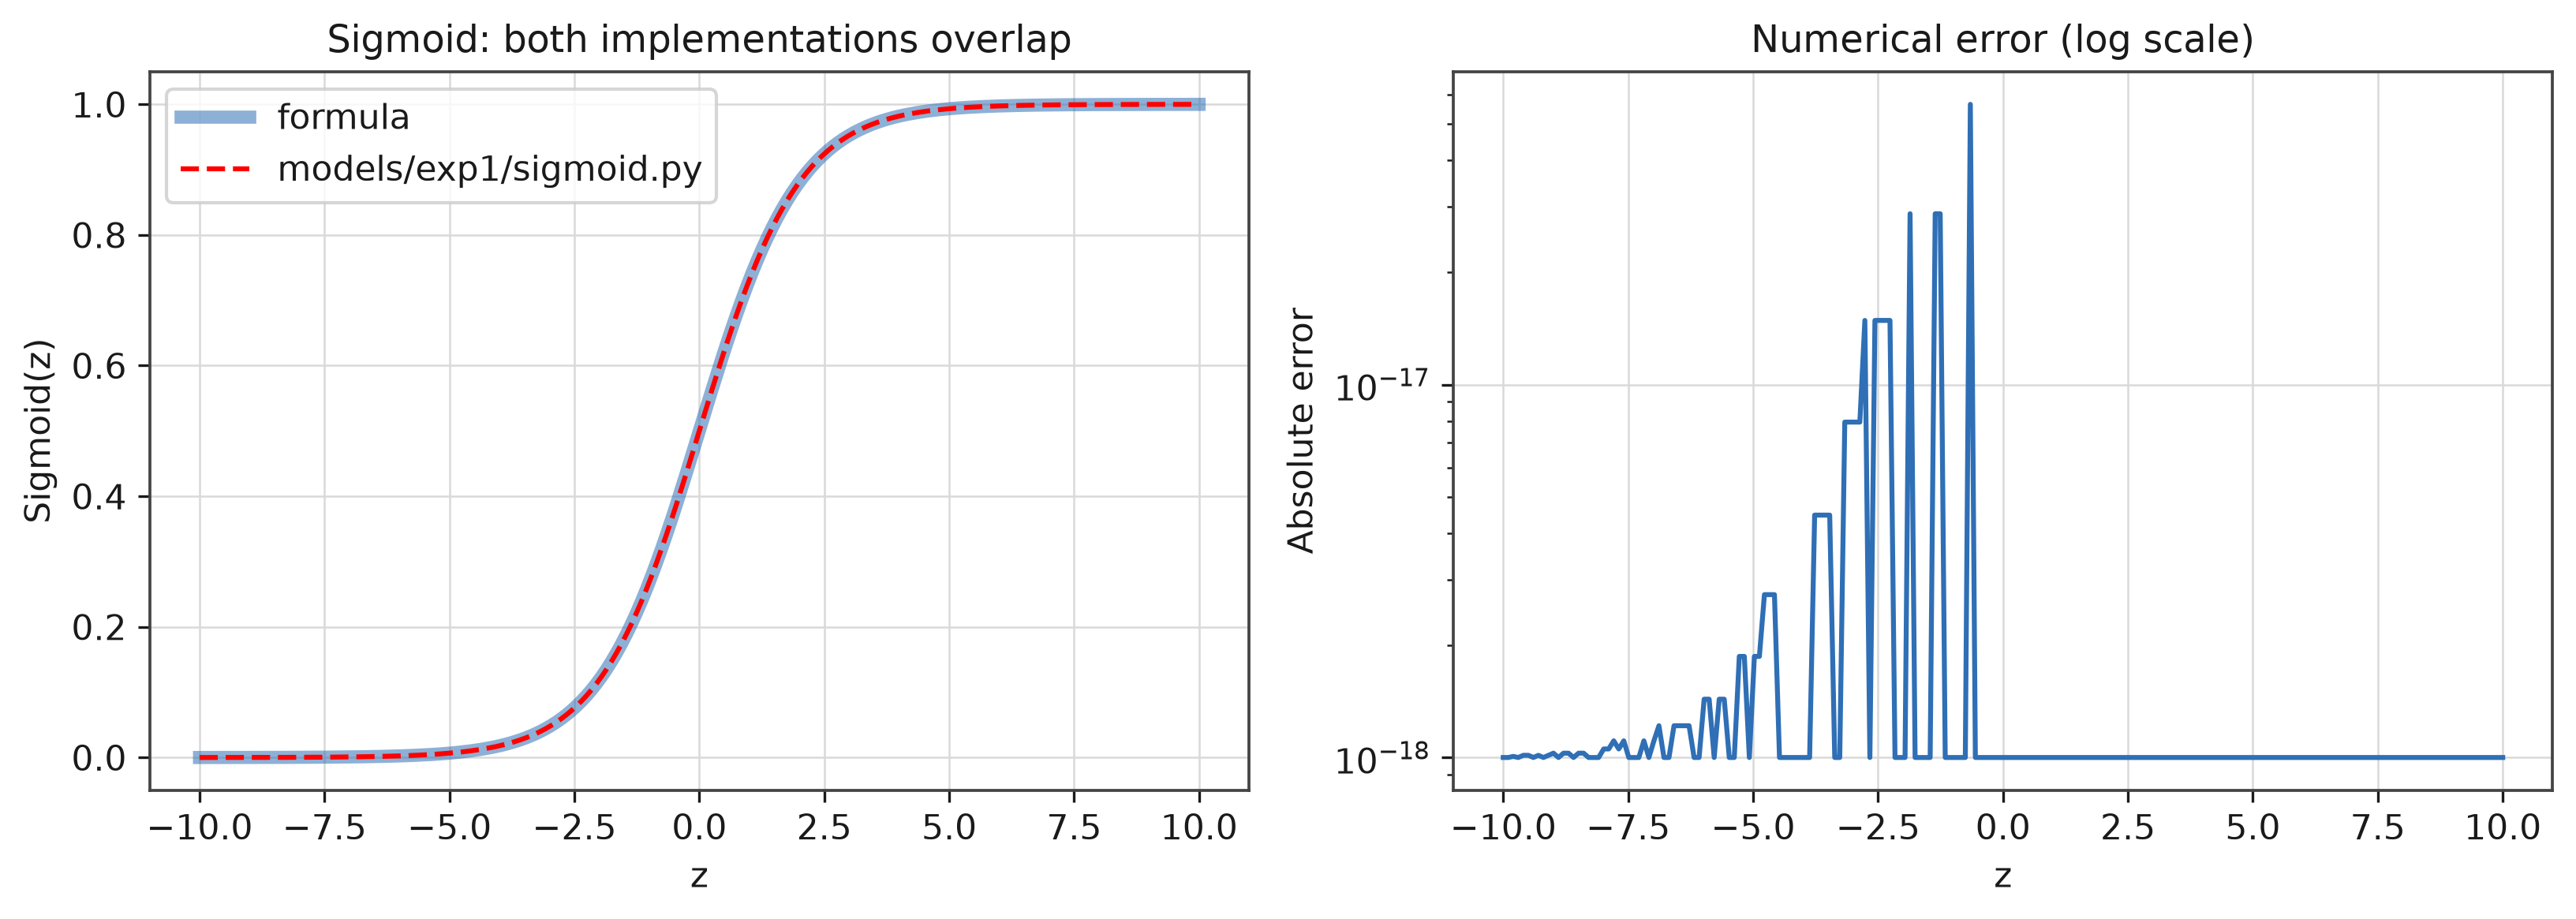

In [5]:
# 自实现的 Sigmoid 与公式实现对比
y_naive = 1 / (1 + np.exp(-z))
y_mine = my_sigmoid(z)

print("公式实现与自实现的最大绝对误差：{:.2e}".format(np.max(np.abs(y_naive - y_mine))))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z, y_naive, label="formula", linewidth=4, alpha=0.55)
axes[0].plot(z, y_mine, "--", color="red", label="models/exp1/sigmoid.py")
axes[0].set_xlabel("z")
axes[0].set_ylabel("Sigmoid(z)")
axes[0].set_title("Sigmoid: both implementations overlap")
axes[0].legend()
axes[0].grid(True)

axes[1].semilogy(z, np.abs(y_naive - y_mine) + 1e-18)
axes[1].set_xlabel("z")
axes[1].set_ylabel("Absolute error")
axes[1].set_title("Numerical error (log scale)")
axes[1].grid(True)

plt.tight_layout()
plt.show()


## b.读取数据集，并画出散点图

In [6]:
data = pd.read_excel('data/exp1/Simmons.xlsx')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Customer  100 non-null    int64  
 1   Spending  100 non-null    float64
 2   Card      100 non-null    int64  
 3   Coupon    100 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 3.3 KB


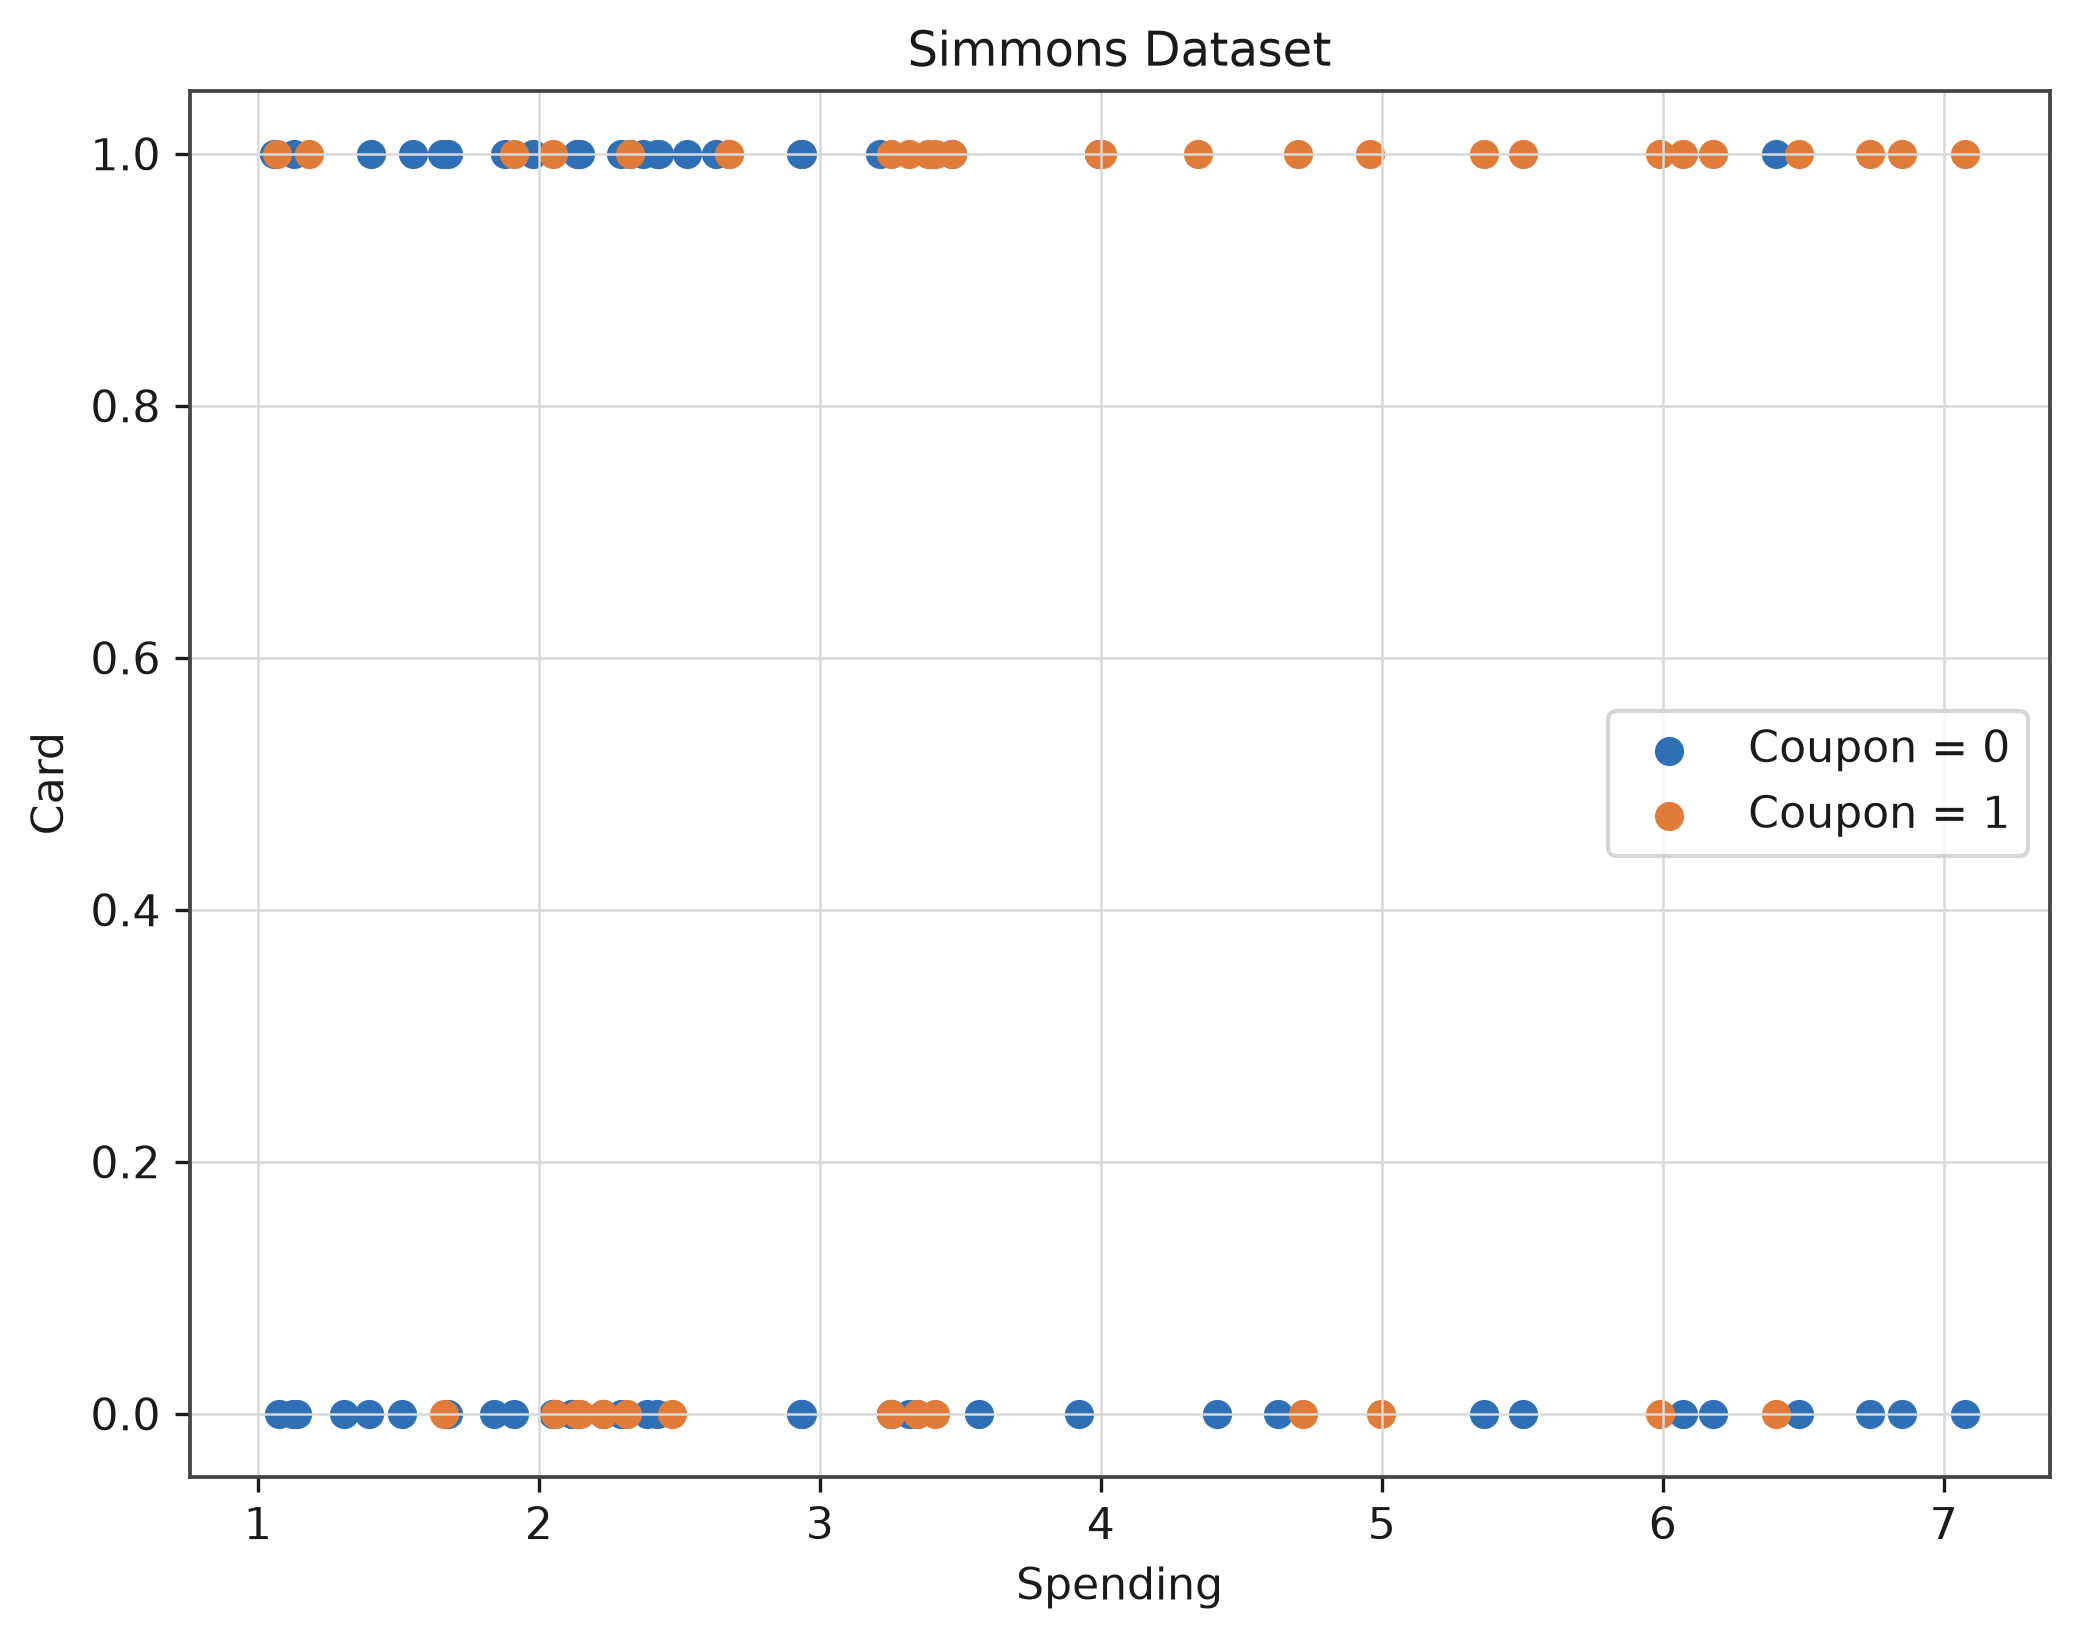

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(data[data["Coupon"] == 0]["Spending"], data[data["Coupon"] == 0]["Card"], label="Coupon = 0")
plt.scatter(data[data["Coupon"] == 1]["Spending"], data[data["Coupon"] == 1]["Card"], label="Coupon = 1")
plt.xlabel("Spending")
plt.ylabel("Card")
plt.title("Simmons Dataset")
plt.legend()
plt.grid(True)
plt.show()

## c.训练Logistic回归模型，并输出最终的分类准确率

In [8]:
X = data[["Spending", "Card"]]
y = data["Coupon"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10086, stratify=y)

In [9]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [10]:
y_pred = model.predict(X_test)

In [11]:
accuracy = accuracy_score(y_test, y_pred)
print("\n最终分类准确率：{:.2f}%".format(accuracy * 100))


最终分类准确率：60.00%


In [12]:
# 自实现：牛顿法
my_model_newton = MyLogisticRegression(solver="newton", C=1.0, n_iters=200, tol=1e-8)
my_model_newton.fit(X_train, y_train)
my_pred_newton = my_model_newton.predict(X_test)

# 自实现：梯度下降
my_model_gd = MyLogisticRegression(solver="gd", learning_rate=0.005, n_iters=5000, tol=1e-8)
my_model_gd.fit(X_train, y_train)
my_pred_gd = my_model_gd.predict(X_test)

print("自实现-牛顿法   准确率：{:.2f}%（迭代 {} 次）".format(
    accuracy_score(y_test, my_pred_newton) * 100, my_model_newton.n_iter_))
print("自实现-梯度下降 准确率：{:.2f}%（迭代 {} 次）".format(
    accuracy_score(y_test, my_pred_gd) * 100, my_model_gd.n_iter_))

comparison = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现-牛顿法", "自实现-梯度下降"],
    "准确率(%)": [accuracy * 100,
                 accuracy_score(y_test, my_pred_newton) * 100,
                 accuracy_score(y_test, my_pred_gd) * 100],
    "w_Spending": [model.coef_[0][0], my_model_newton.coef_[0][0], my_model_gd.coef_[0][0]],
    "w_Card": [model.coef_[0][1], my_model_newton.coef_[0][1], my_model_gd.coef_[0][1]],
    "截距 b": [model.intercept_[0], my_model_newton.intercept_[0], my_model_gd.intercept_[0]],
})
print("\n三种实现的结果对比：")
print(comparison.round(4).to_string(index=False))


自实现-牛顿法   准确率：60.00%（迭代 4 次）
自实现-梯度下降 准确率：60.00%（迭代 1432 次）

三种实现的结果对比：
      实现方式  准确率(%)  w_Spending  w_Card    截距 b
sklearn 调包    60.0      0.4227   1.265 -2.5224
   自实现-牛顿法    60.0      0.4226   1.265 -2.5224
  自实现-梯度下降    60.0      0.4226   1.265 -2.5224


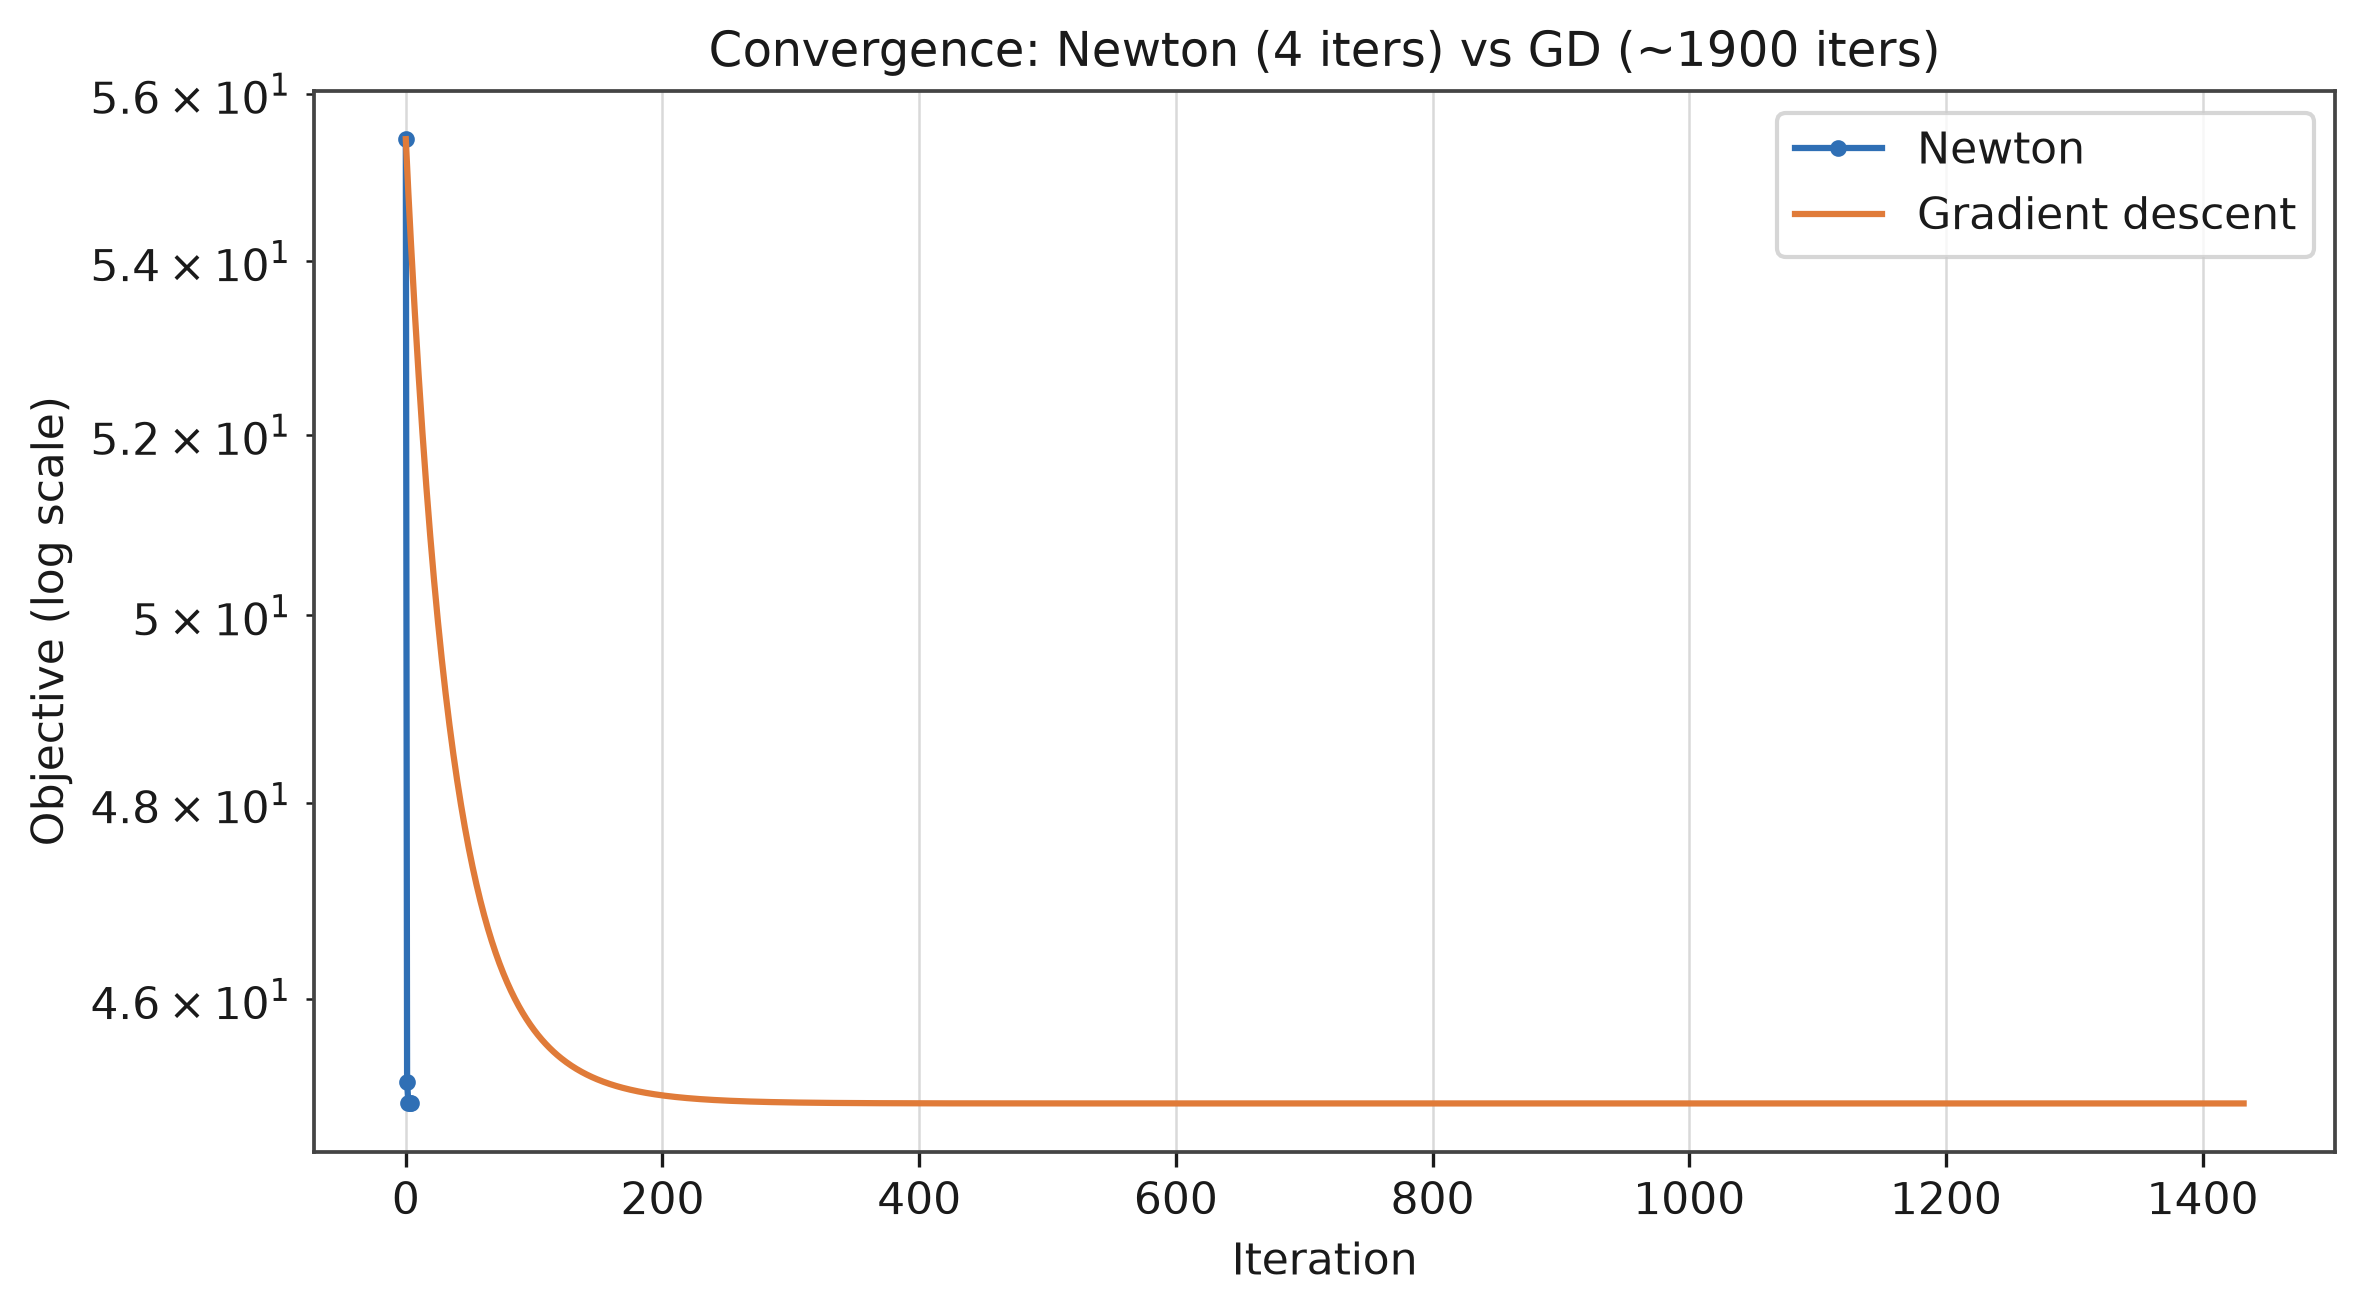

In [13]:
plt.figure(figsize=(8, 4.5))
plt.plot(my_model_newton.loss_history_, marker="o", markersize=3, label="Newton")
plt.plot(my_model_gd.loss_history_, label="Gradient descent")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Objective (log scale)")
plt.title("Convergence: Newton (4 iters) vs GD (~1900 iters)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## d.绘制Logistic回归模型的决策边界

In [14]:
beta0 = model.intercept_[0]
beta1 = model.coef_[0][0]
beta2 = model.coef_[0][1]

spending_range = np.linspace(
    X["Spending"].min(),
    X["Spending"].max(),
    200
)

card_boundary = -(beta0 + beta1 * spending_range) / beta2

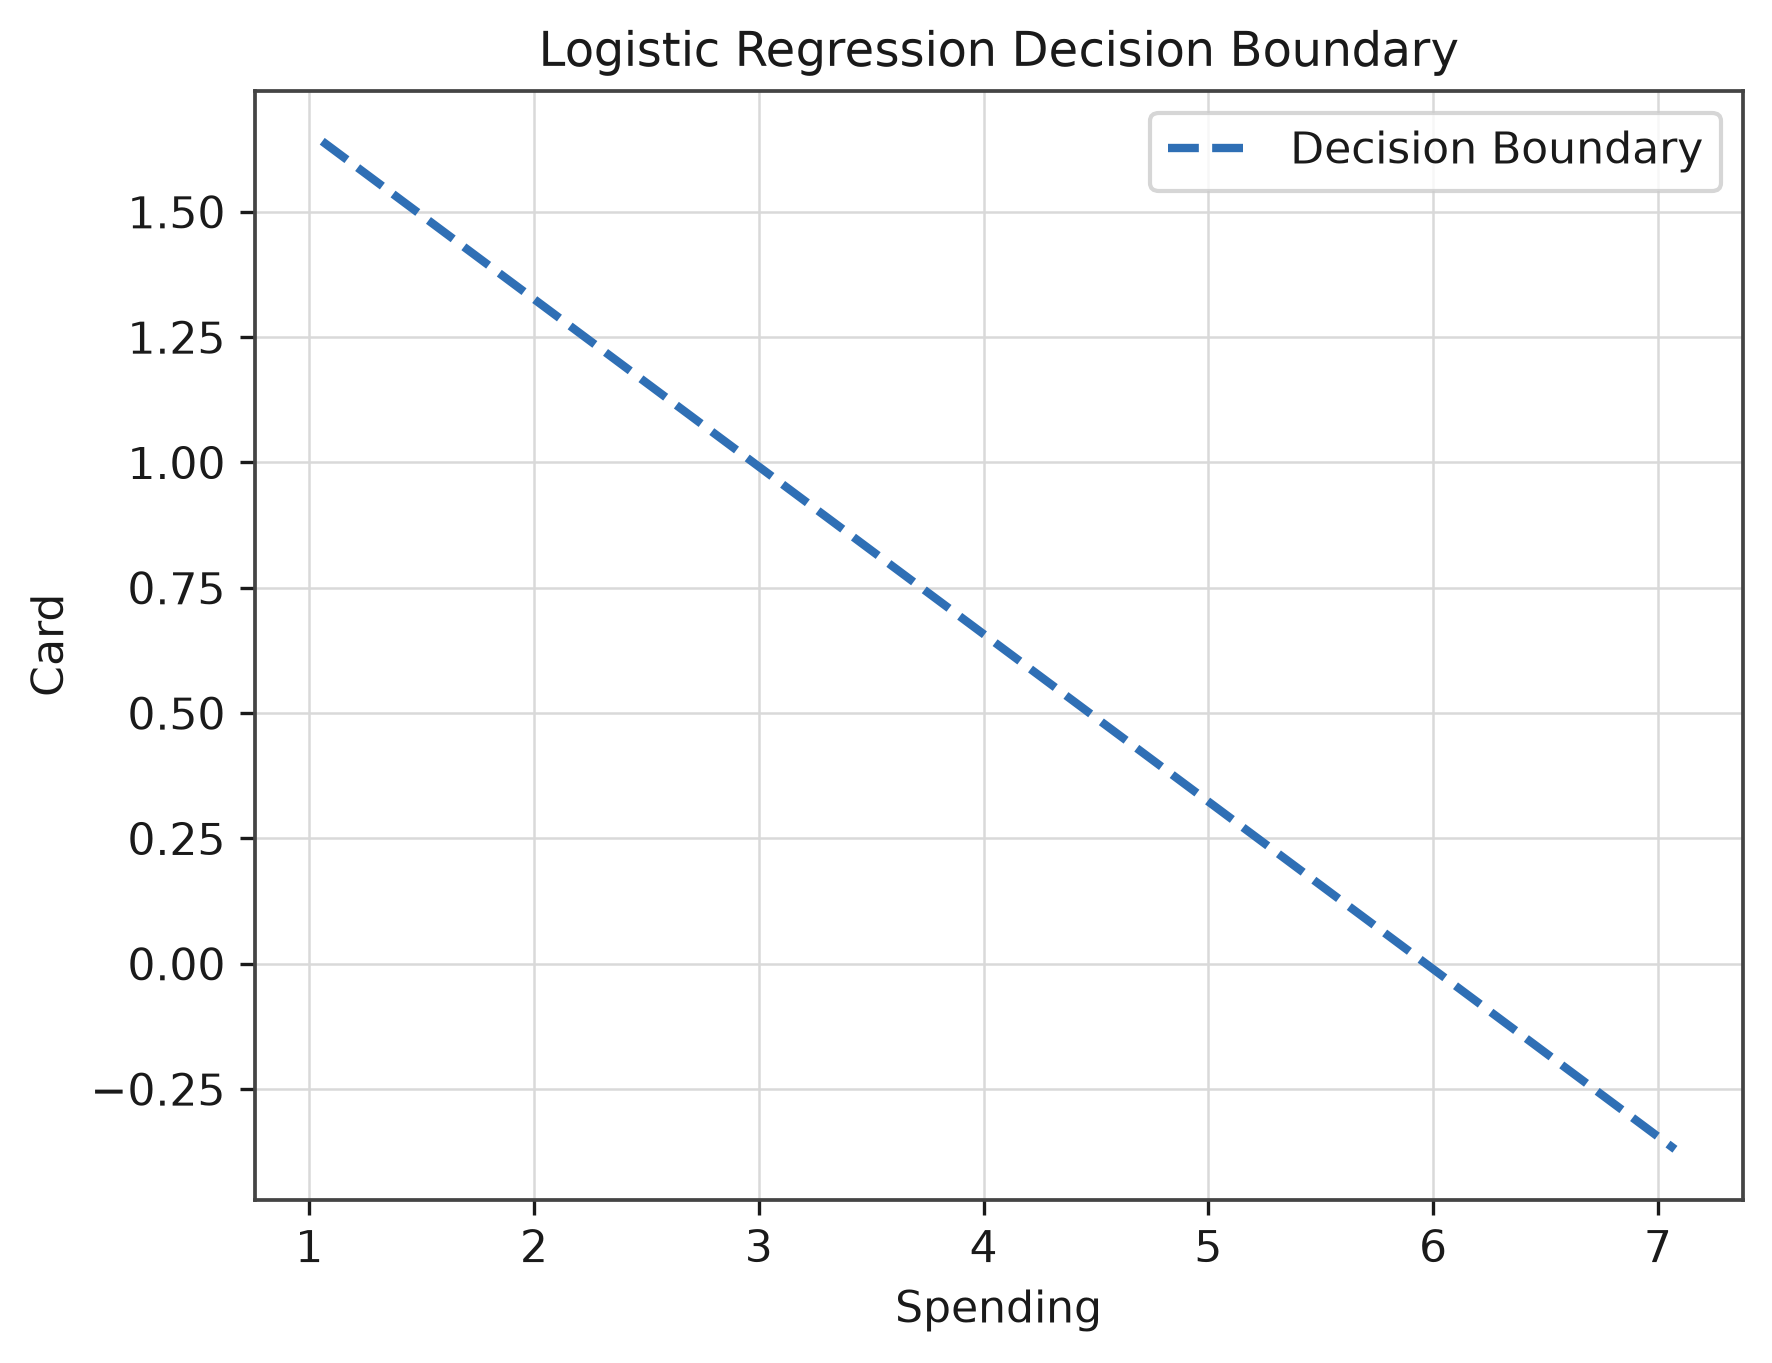

In [15]:
plt.plot(spending_range,
    card_boundary,
    linestyle="--",
    linewidth=2,
    label="Decision Boundary"
)
plt.xlabel("Spending")
plt.ylabel("Card")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid(True)
plt.show()

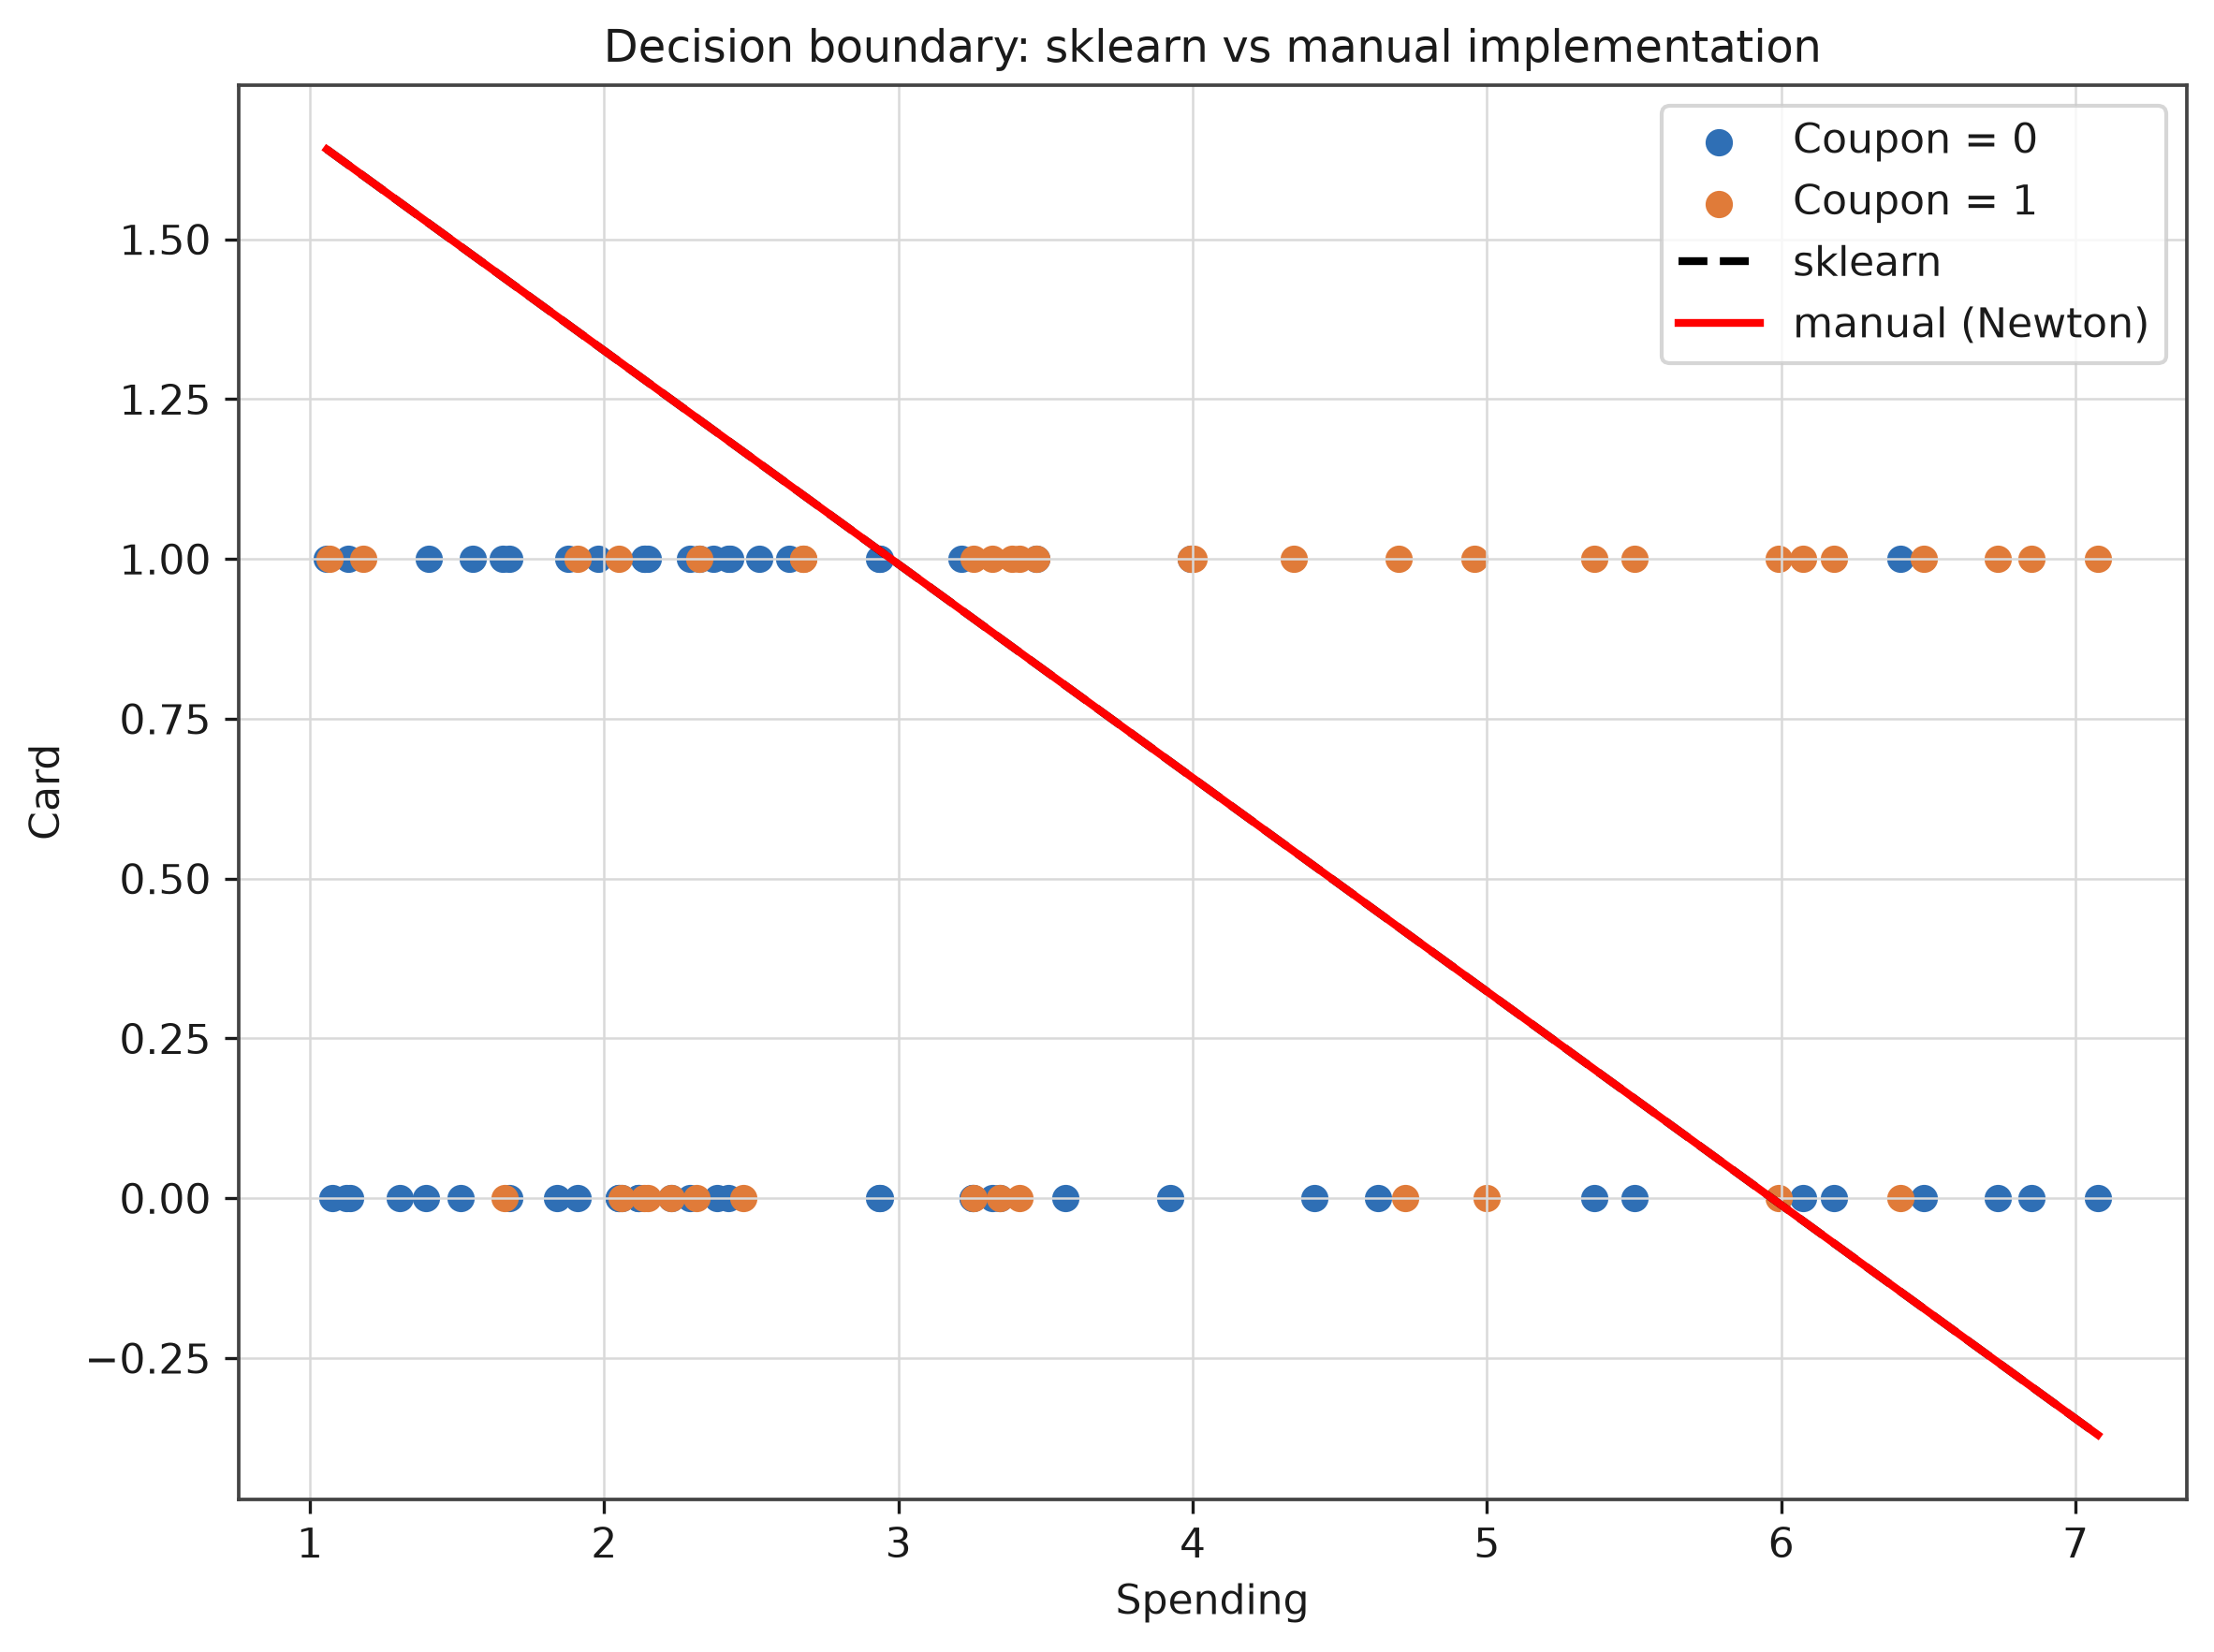

两条边界的最大差异：3.29e-05


In [16]:
# 自实现（牛顿法）的决策边界
wn, bn = my_model_newton.coef_[0], my_model_newton.intercept_[0]
card_boundary_mine = -(bn + wn[0] * spending_range) / wn[1]

plt.figure(figsize=(8, 6))
plt.scatter(data[data["Coupon"] == 0]["Spending"], data[data["Coupon"] == 0]["Card"],
            label="Coupon = 0")
plt.scatter(data[data["Coupon"] == 1]["Spending"], data[data["Coupon"] == 1]["Card"],
            label="Coupon = 1")
plt.plot(spending_range, card_boundary, "k--", linewidth=2, label="sklearn")
plt.plot(spending_range, card_boundary_mine, "r-", linewidth=2, label="manual (Newton)")
plt.xlabel("Spending")
plt.ylabel("Card")
plt.title("Decision boundary: sklearn vs manual implementation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("两条边界的最大差异：{:.2e}".format(
    np.max(np.abs(card_boundary - card_boundary_mine))))


# 二、线性判别分析

## a.编写Python代码实现线性判别分析

In [17]:
# 调包实现
lda = LinearDiscriminantAnalysis()

# 自实现
my_lda = MyLDA()


## b.加载鸢尾花数据集，并对数据进行预处理和可视化

In [18]:
iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

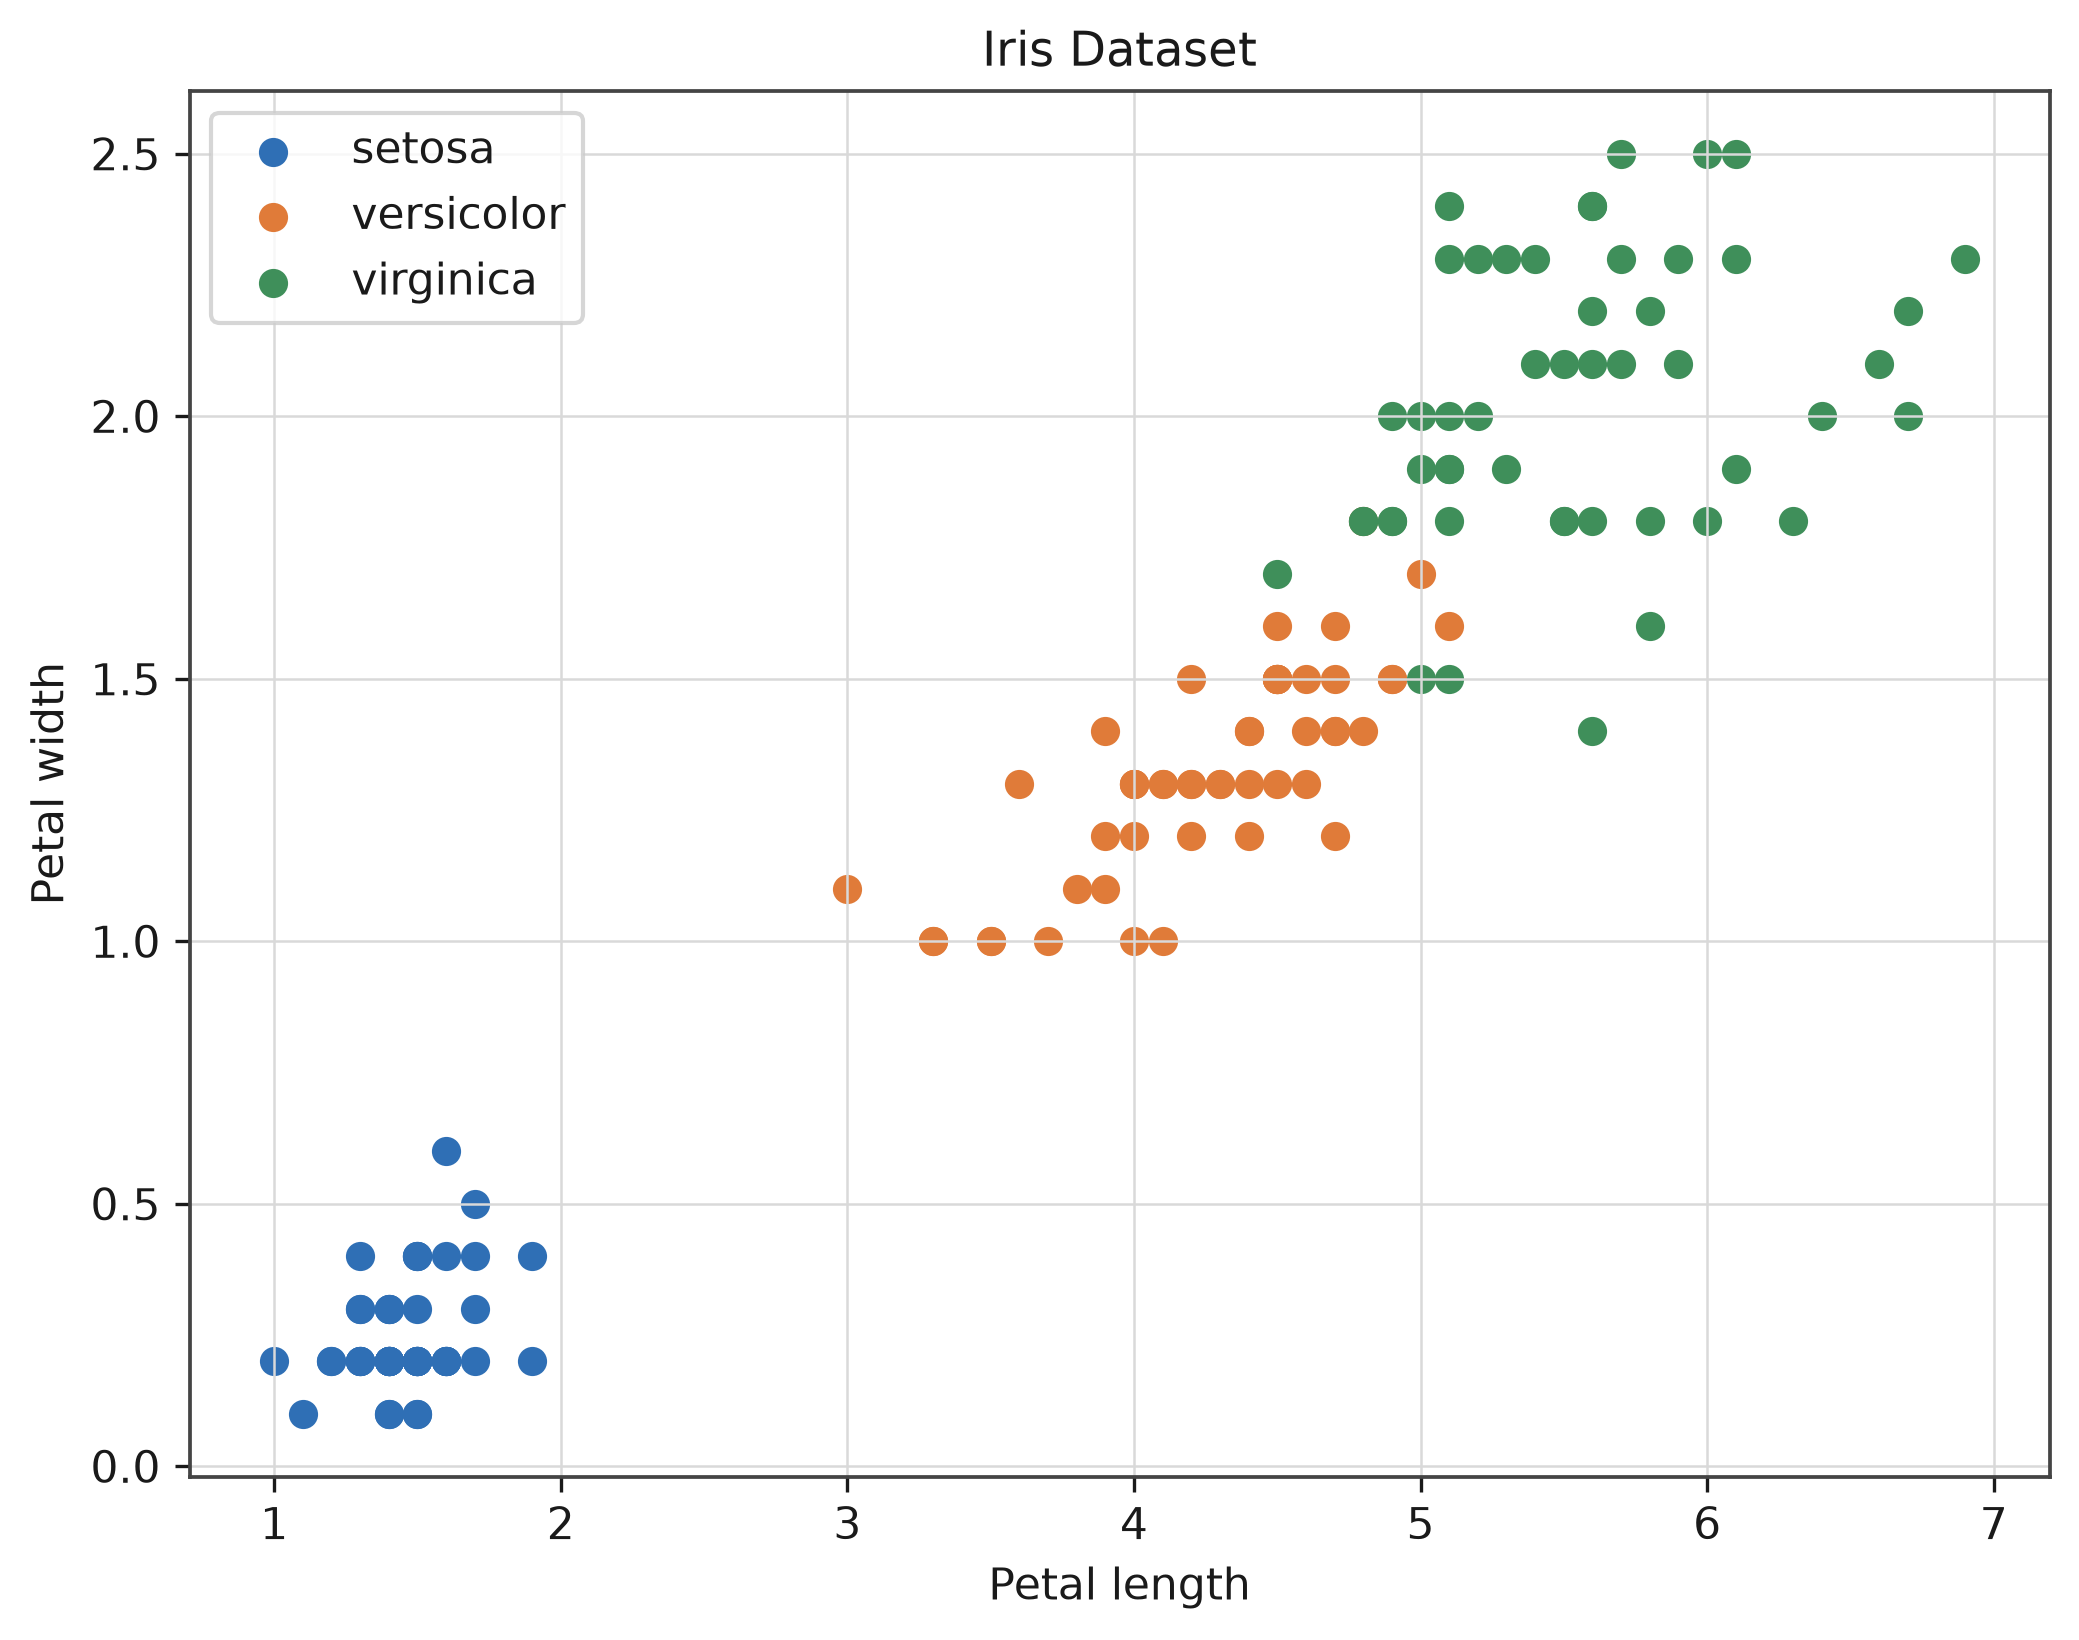

In [20]:
plt.figure(figsize=(8, 6))

for i, name in enumerate(iris.target_names):
    plt.scatter(X[y == i, 2], X[y == i, 3], label=name)

plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.title("Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

## c.使用LDA进行分类，并输出模型的准确率、混淆均值等评估指标

In [21]:
lda.fit(X_train_scaled, y_train)
y_pred = lda.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print("LDA 分类准确率：{:.2f}%".format(accuracy * 100))

LDA 分类准确率：100.00%


In [22]:
cm = confusion_matrix(y_test, y_pred)
print("混淆矩阵：")
print(cm)

混淆矩阵：
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


In [23]:
print("\n分类报告：")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


分类报告：
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



两种 LDA 实现的结果对比：
      实现方式  准确率(%)  训练集类别均值数  判别方向数
sklearn 调包   100.0         3      2
       自实现   100.0         3      2

两种实现的预测完全一致： True


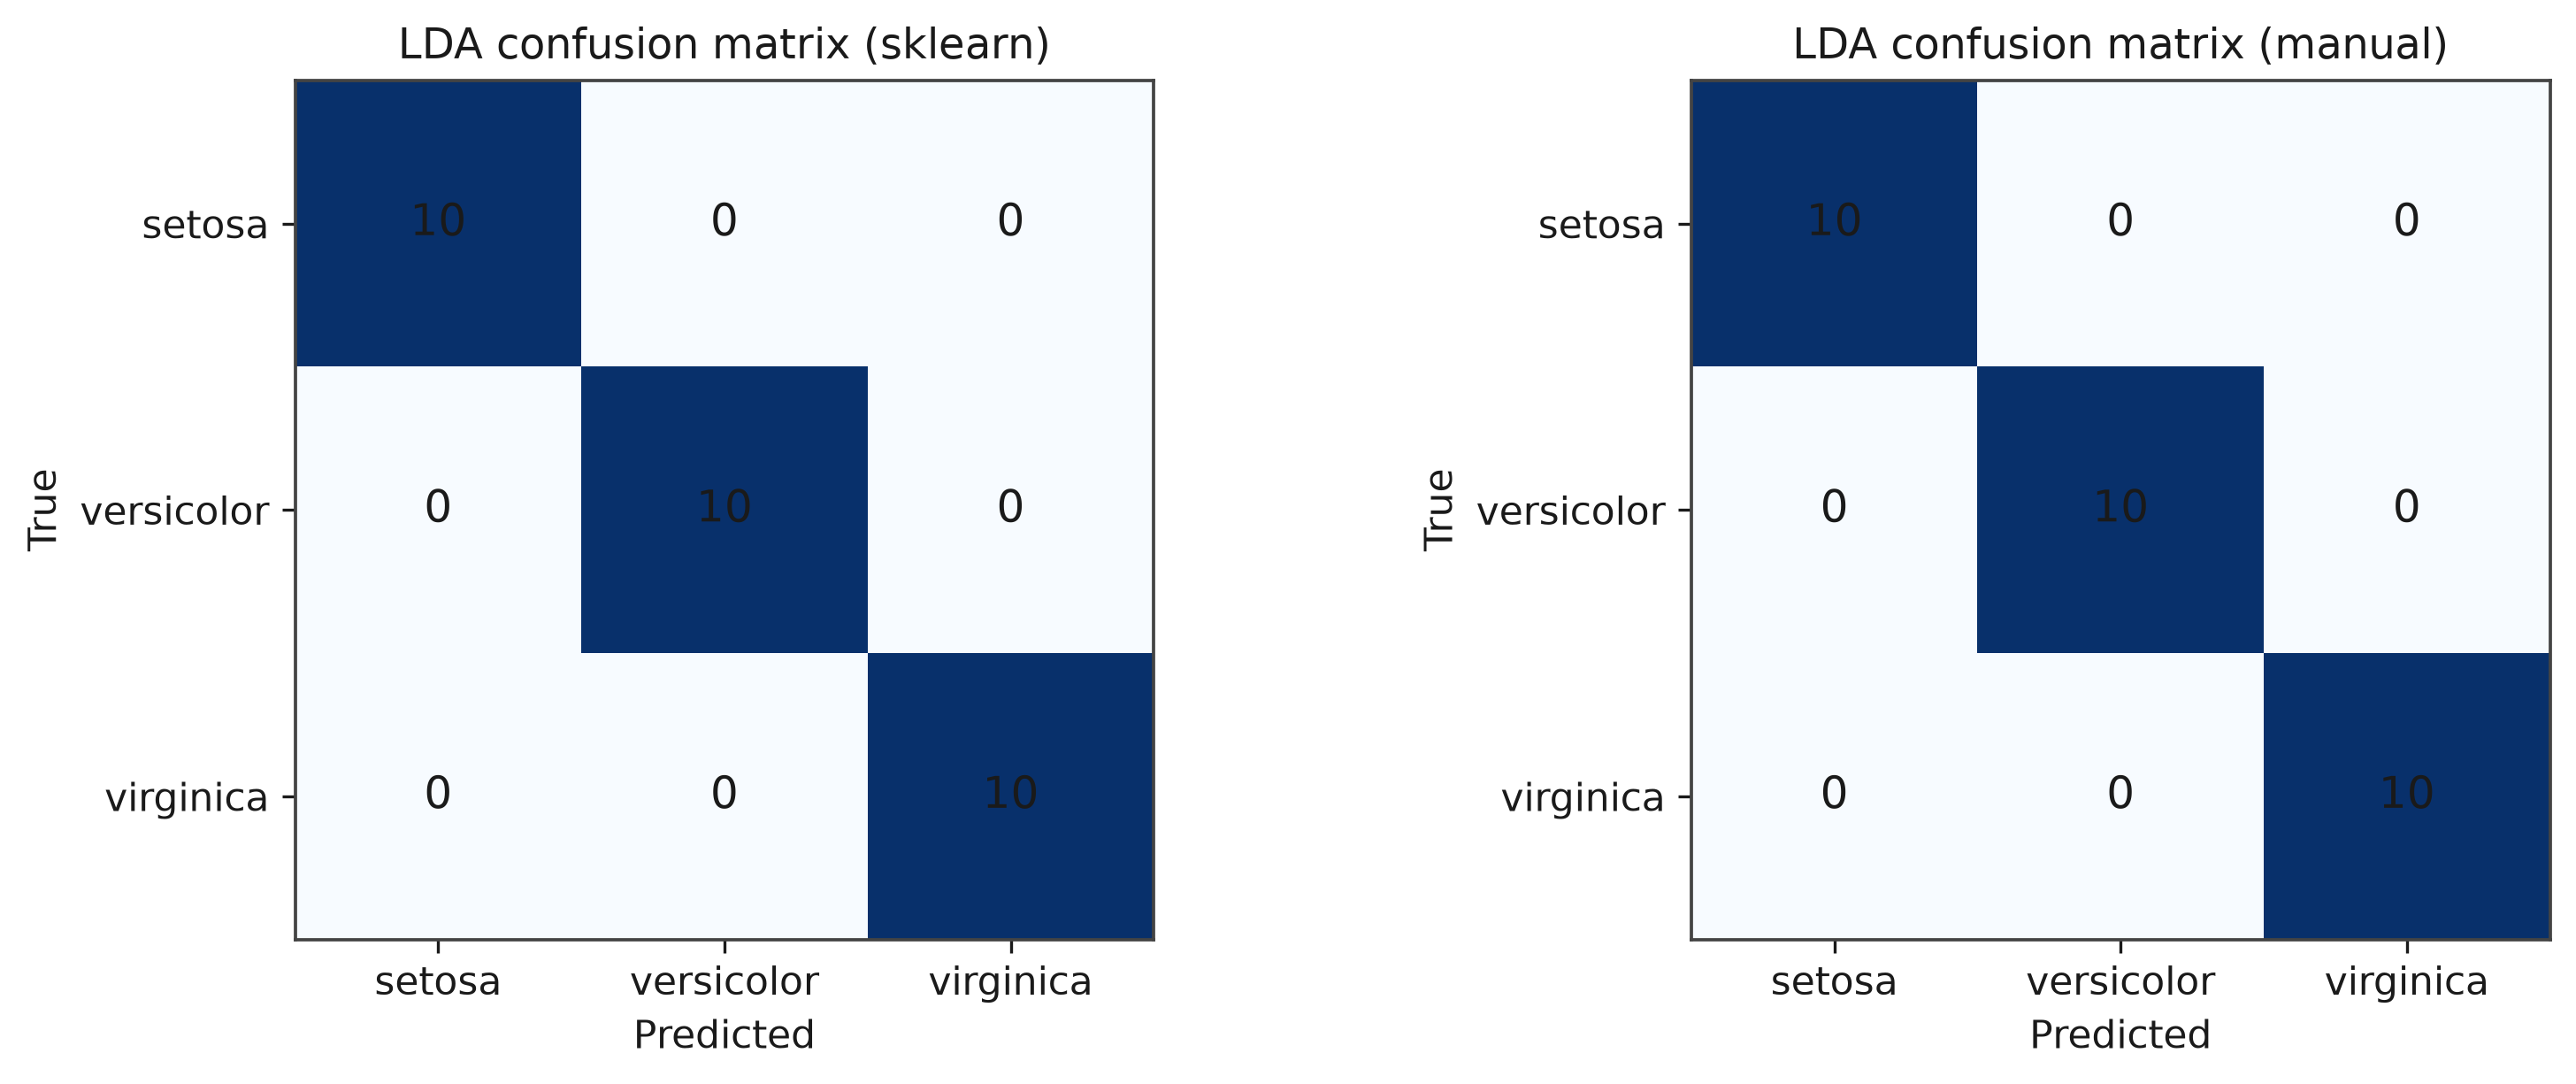

In [24]:
# 自实现 LDA：训练与预测
my_lda.fit(X_train_scaled, y_train)
my_pred_lda = my_lda.predict(X_test_scaled)

comparison_lda = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现"],
    "准确率(%)": [accuracy_score(y_test, y_pred) * 100,
                 accuracy_score(y_test, my_pred_lda) * 100],
    "训练集类别均值数": [lda.means_.shape[0], my_lda.means_.shape[0]],
    "判别方向数": [lda.scalings_.shape[1], my_lda.scalings_.shape[1]],
})
print("两种 LDA 实现的结果对比：")
print(comparison_lda.to_string(index=False))
print("\n两种实现的预测完全一致：", bool((my_pred_lda == y_pred).all()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (cm_show, title) in zip(axes, [
        (confusion_matrix(y_test, y_pred), "sklearn"),
        (confusion_matrix(y_test, my_pred_lda), "manual")]):
    im = ax.imshow(cm_show, cmap="Blues")
    for i in range(cm_show.shape[0]):
        for j in range(cm_show.shape[1]):
            ax.text(j, i, cm_show[i, j], ha="center", va="center", fontsize=12)
    ax.set_xticks(range(3), iris.target_names)
    ax.set_yticks(range(3), iris.target_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"LDA confusion matrix ({title})")
fig.tight_layout()
plt.show()


## d.将LDA投影结果可视化，观察不同类型的分布情况

In [25]:
X_lda = lda.transform(X_train_scaled)
print("LDA 投影后的数据形状：", X_lda.shape)

LDA 投影后的数据形状： (120, 2)


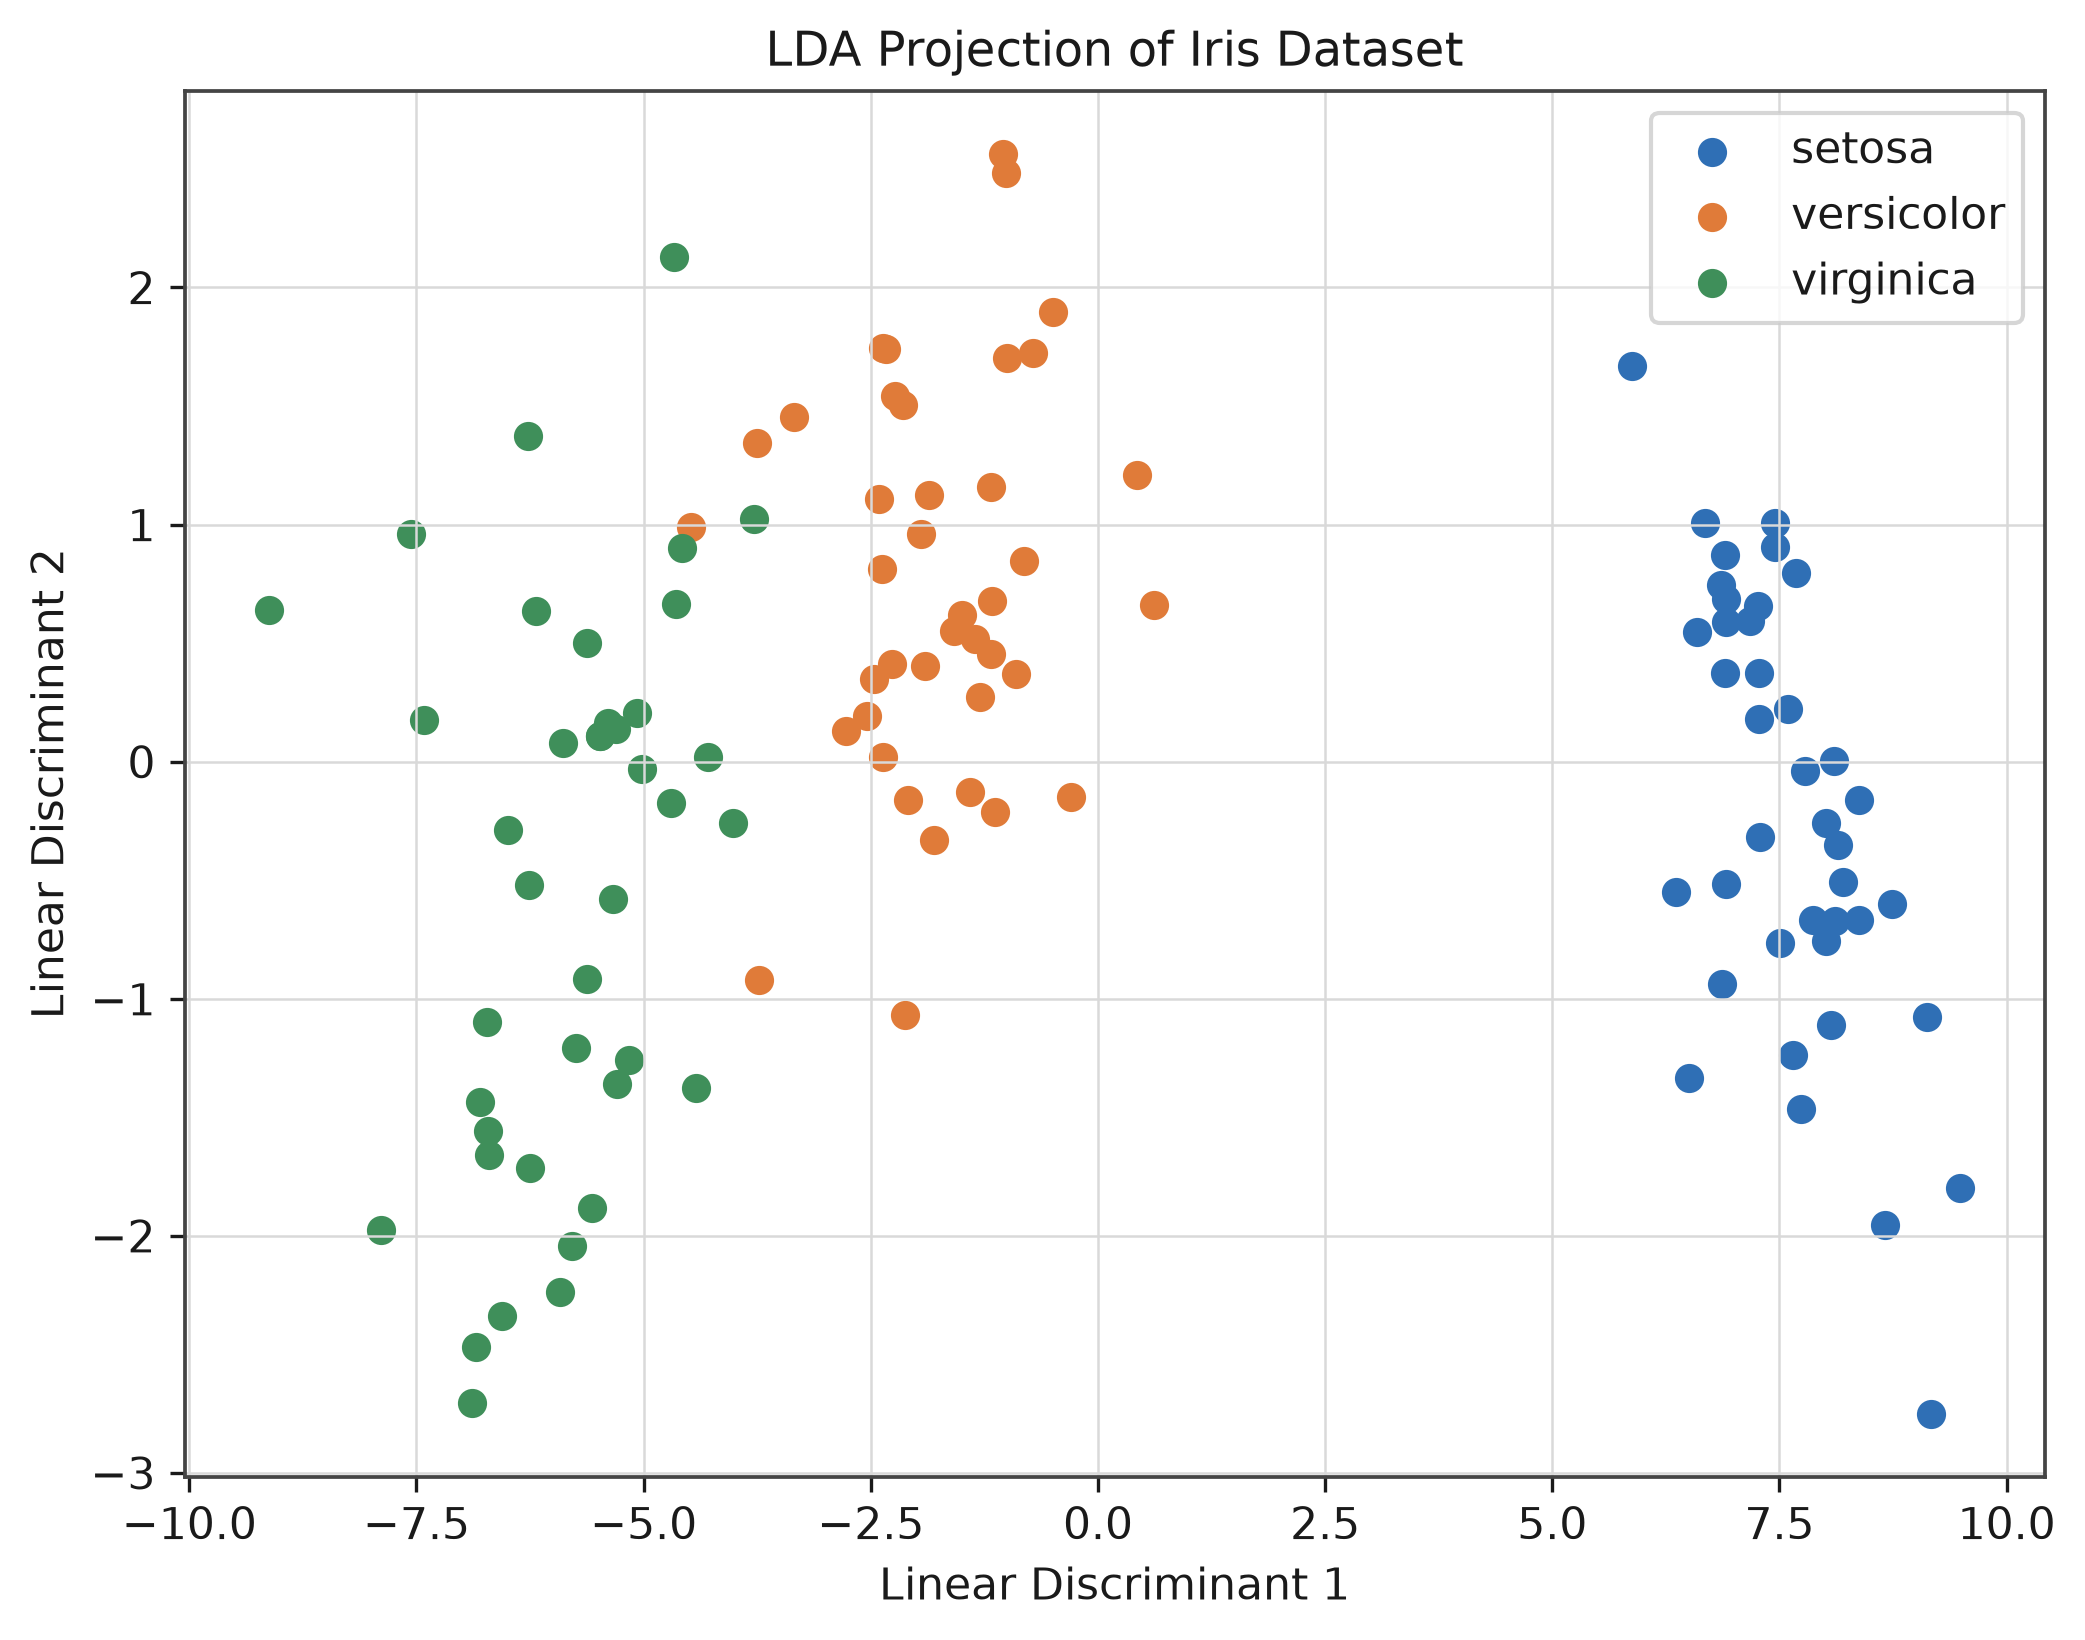

In [26]:
plt.figure(figsize=(8, 6))

for i, name in enumerate(iris.target_names):
    plt.scatter(X_lda[y_train == i, 0], X_lda[y_train == i, 1], label=name)

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA Projection of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

两种投影的相关系数： [1.0, 1.0]


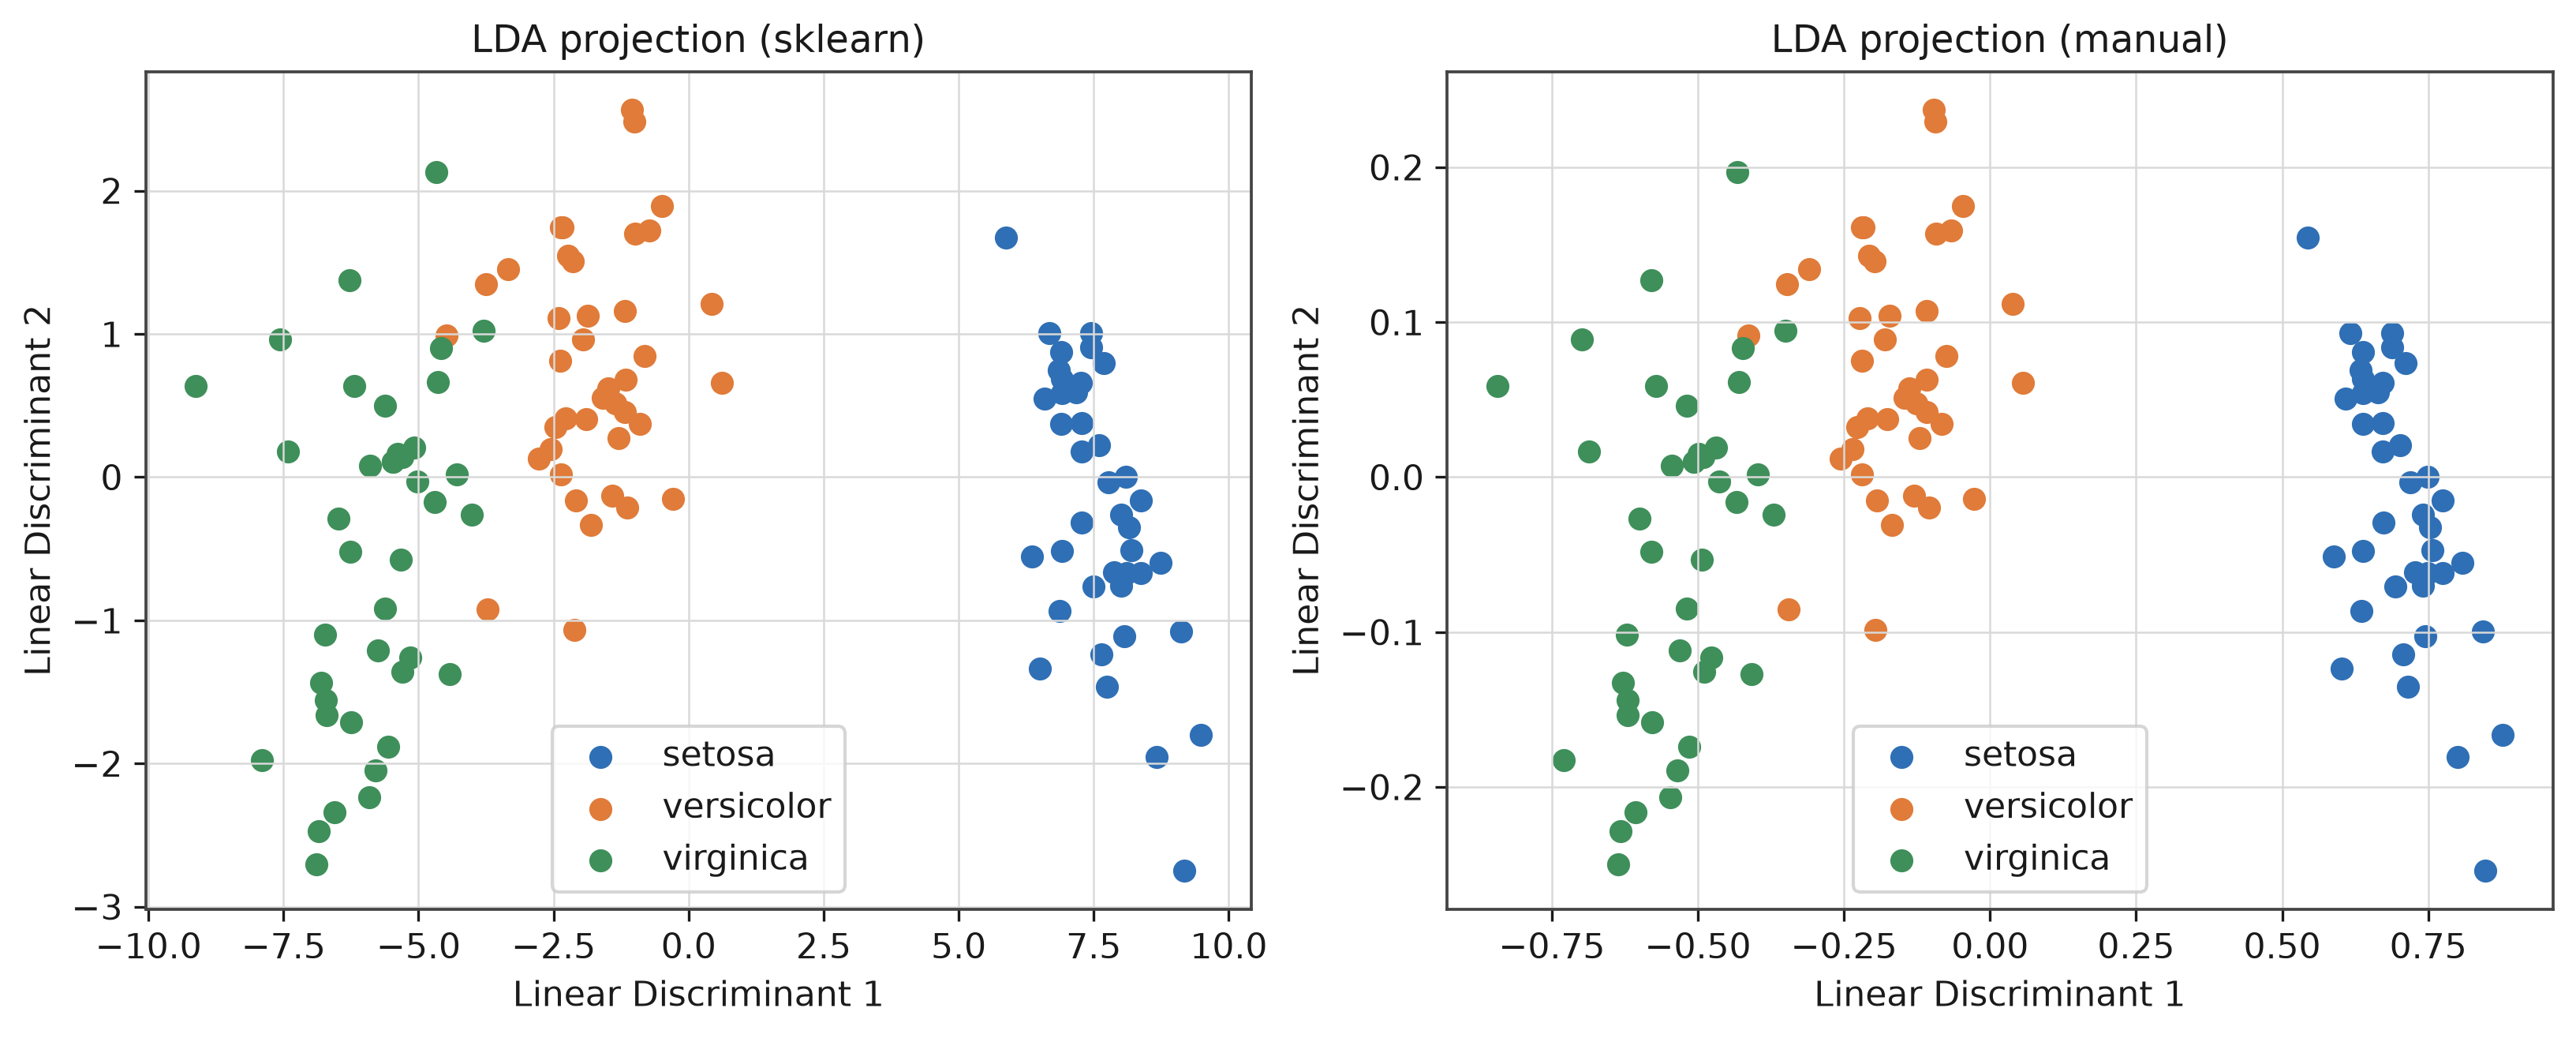

In [27]:
# 自实现的 LDA 投影
X_lda_mine = my_lda.transform(X_train_scaled)

# 两种投影可能相差一个符号与尺度，这里统一符号后比较
signs = np.sign(np.sum(X_lda * X_lda_mine, axis=0))
X_lda_mine_aligned = X_lda_mine * signs
print("两种投影的相关系数：", [round(float(np.corrcoef(X_lda[:, i], X_lda_mine_aligned[:, i])[0, 1]), 6)
                              for i in range(X_lda.shape[1])])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (Z, title) in zip(axes, [(X_lda, "sklearn"), (X_lda_mine_aligned, "manual")]):
    for i, name in enumerate(iris.target_names):
        ax.scatter(Z[y_train == i, 0], Z[y_train == i, 1], label=name)
    ax.set_xlabel("Linear Discriminant 1")
    ax.set_ylabel("Linear Discriminant 2")
    ax.set_title(f"LDA projection ({title})")
    ax.legend()
    ax.grid(True)
fig.tight_layout()
plt.show()
